# Q-Control-Optimization: choosing backup lines of a substation on a quantum computer

The notebook is built from the project files: every code cell is a file from `src/`, copied 1:1.
**Run the cells from top to bottom** (Shift+Enter). The results appear in the `results/` folder next to the notebook.

| Cell | What it does | Time |
|---|---|---|
| API key | reads the key from `key.txt` into the kernel memory (needed only for step 4) | - |
| Settings | writes `data/config.json` | instant |
| Shared functions | defines the functions used by all steps, prints nothing | instant |
| Step 1 | problem, energies of all 16 states, optimum by brute force | < 1 s |
| Step 2 | quantum circuits, angle tuning, theory | a few seconds |
| Step 3 | CPUQVM simulator (no internet) - optional | < 1 s |
| Step 4 | submission to the Wukong 180-2 quantum computer and collection of the result | seconds per run |
| Step 5 | comparison of theory, simulator and QPU, plot | ~1 s |

## API key
Create the file `key.txt` next to the notebook (File -> New -> Text File) and paste only the key from the
OriginQC console into it - one line, no quotes and no `api_key =`. The key does not get into the notebook and is not printed.

In [1]:
# ===== API key =====
# The key is stored in the file key.txt next to the notebook (or in src/key.txt): one line, the key only.
# To create the file in JupyterLab: File -> New -> Text File, paste the key, save as key.txt.
# The cell puts the key into the kernel memory for step 4. The key itself is never printed.
import os
os.environ.pop("ORIGINQC_API_KEY", None)          # forget a key entered earlier through an input field
for path in ("key.txt", os.path.join("src", "key.txt")):
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            lines = [l.strip().strip('"').strip("'").strip() for l in f.read().replace("\ufeff", "").splitlines()]
        key = next((l for l in lines if l), "")
        os.environ["ORIGINQC_API_KEY"] = key
        warn = " - WARNING: the key contains a space or '='" if any(c.isspace() or c == "=" for c in key) else ""
        print(f"Key taken from {path}: length {len(key)} characters{warn}")
        break
else:
    print("No key.txt next to the notebook - create it (see the comment above)")

Key taken from key.txt: length 128 characters


## Settings
The problem (line losses, constraints, penalties) and the run parameters. The most important for a run:
`shots` - how many times each circuit is executed, `qpu_backend` - the quantum computer
(`WK_C180`, `WK_C180_2`, `WK_C180_3`), `qpu_circuits` - which circuits are sent to it,
`cloud_simulator` - cloud simulator (off: `null`).

In [2]:
# ===== data/config.json - problem and run parameters =====
# This cell writes data/config.json next to the notebook. Parameters can be changed right here.
import json, os
CONFIG = json.loads("""
{
  "n_vars": 4,
  "objective_costs": [1.2, 0.8, 1.5, 0.9],
  "equality_constraints": [
    {"indices": [0, 1, 2, 3], "target_sum": 2, "penalty": 50.0}
  ],
  "inequality_constraints": [
    {"indices": [0, 3], "penalty": 100.0, "type": "mutual_exclusion"}
  ],
  "experiment": {
    "shots": 1000,
    "xy_conflict_penalty": 1.0,
    "legacy_angles": {"gamma": 0.5, "beta": 0.3},
    "cloud_simulator": null,
    "qpu_backend": "WK_C180_2",
    "qpu_circuits": ["calib", "penalty_qaoa", "xy_qaoa"],
    "qpu_amend": true,
    "time_budget_sec": 35
  }
}
""")
os.makedirs("data", exist_ok=True)
with open("data/config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)
print("Written data/config.json:", json.dumps(CONFIG["experiment"], ensure_ascii=False))

Written data/config.json: {"shots": 1000, "xy_conflict_penalty": 1.0, "legacy_angles": {"gamma": 0.5, "beta": 0.3}, "cloud_simulator": null, "qpu_backend": "WK_C180_2", "qpu_circuits": ["calib", "penalty_qaoa", "xy_qaoa"], "qpu_amend": true, "time_budget_sec": 35}


## Shared functions (src/common.py)
QUBO construction, gates and circuits, exact simulator, angle tuning, metrics, parsing of the backend's answers.
The cell only defines functions - there is no output. Run it before the steps.

In [3]:
# ===== src/common.py (project file, 1:1) =====
# -*- coding: utf-8 -*-
"""
common.py - shared functions used by all steps of the project.

Sections:
  1. Paths and JSON files
  2. Problem: QUBO, energies, feasibility (step 1)
  3. Gates and circuits - only H, X, RX, RZ, CNOT (step 2)
  4. Exact numpy simulator and angle tuning (step 2)
  5. Quality metrics (steps 3-5)
  6. Result keys and bit order (steps 3-5)
  7. Converting a circuit into a pyqpanda3 program (steps 3-4)

Index convention: state x = (x0, x1, x2, x3), x_i = 1 means line i is switched on.
In probability arrays the index is k = int("x0x1x2x3", 2), i.e. x0 is the most significant bit.
"""
import json
import math
import os
from itertools import product

import numpy as np

PI = math.pi

# ============================================================================ 1. Paths and JSON files
# As a file (python, %run): the project folder above src/; as code in a notebook cell: the notebook folder.
SRC_DIR = os.path.dirname(os.path.abspath(globals().get("__file__", os.path.join(os.getcwd(), "src", "common.py"))))
ROOT = os.path.dirname(SRC_DIR)
CONFIG_PATH = os.path.join(ROOT, "data", "config.json")
RESULTS_DIR = os.path.join(ROOT, "results")
STEP1_PATH = os.path.join(RESULTS_DIR, "step1_problem.json")
STEP2_PATH = os.path.join(RESULTS_DIR, "step2_circuits.json")
STEP3_PATH = os.path.join(RESULTS_DIR, "step3_local.json")
STEP4_PATH = os.path.join(RESULTS_DIR, "step4_cloud.json")
STEP5_REPORT = os.path.join(RESULTS_DIR, "step5_report.md")
STEP5_PLOT = os.path.join(RESULTS_DIR, "step5_plot.png")


def to_jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_jsonable(v) for v in obj.tolist()]
    if isinstance(obj, (np.floating, np.integer, np.bool_)):
        return obj.item()
    if isinstance(obj, (bool, int, float, str)) or obj is None:
        return obj
    return str(obj)


def save_json(path, obj):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(to_jsonable(obj), f, indent=1, ensure_ascii=False)
    os.replace(tmp, path)          # the file is never left half-written


def load_json(path, hint):
    if not os.path.exists(path):
        raise SystemExit(f"Missing file {os.path.relpath(path, ROOT)} - run {hint} first.")
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def load_config():
    with open(CONFIG_PATH, encoding="utf-8") as f:
        return json.load(f)


def pyqpanda3_version():
    try:
        from importlib.metadata import version
        return version("pyqpanda3")
    except Exception:  # noqa: BLE001
        return "not installed"


def rel(path):
    return os.path.relpath(path, ROOT)


# ============================================================================ 2. Problem
def build_qubo(cfg):
    """H(x) = x^T Q x + offset: line losses + penalties for violated constraints (as in the original qubo_builder.py)."""
    n = cfg["n_vars"]
    Q = np.zeros((n, n))
    offset = 0.0
    for i in range(n):
        Q[i, i] += cfg["objective_costs"][i]
    for ec in cfg.get("equality_constraints", []):           # P * (sum x_i - t)^2
        P, idx, t = ec["penalty"], ec["indices"], ec["target_sum"]
        for i in idx:
            Q[i, i] += P * (1 - 2 * t)                       # x_i^2 = x_i
            for j in idx:
                if j > i:
                    Q[i, j] += P
                    Q[j, i] += P
        offset += P * t ** 2
    for ic in cfg.get("inequality_constraints", []):         # P * x_i * x_j
        P = ic["penalty"]
        i, j = ic["indices"]
        Q[i, j] += P / 2
        Q[j, i] += P / 2
    return Q, offset


def violations(x, cfg):
    """List of violated constraints (empty - the state is feasible)."""
    out = []
    for ec in cfg.get("equality_constraints", []):
        s = sum(x[i] for i in ec["indices"])
        if s != ec["target_sum"]:
            out.append(f"lines on: {s} (need {ec['target_sum']})")
    for ic in cfg.get("inequality_constraints", []):
        i, j = ic["indices"]
        if x[i] and x[j]:
            out.append(f"short circuit: lines {i} and {j} together")
    return out


def qubo_to_ising(Q):
    """x_i = (1 - Z_i)/2  ->  H = const + sum h_i Z_i + sum_{i<j} J_ij Z_i Z_j."""
    n = len(Q)
    h = np.zeros(n)
    J = np.zeros((n, n))
    for i in range(n):
        h[i] = -Q[i, i] / 2.0
        for j in range(n):
            if i != j:
                h[i] -= (Q[i, j] + Q[j, i]) / 4.0
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = (Q[i, j] + Q[j, i]) / 4.0
    return h, J


def energies(Q, offset, states):
    return np.array([float(np.array(x) @ Q @ np.array(x) + offset) for x in states])


def xstr(k, n):
    return format(k, f"0{n}b")      # string x0 x1 ... x_{n-1}


class Problem:
    """Everything about the problem: 16 states, their energies, feasibility, classical optimum (brute force)."""

    def __init__(self, cfg):
        self.cfg = cfg
        self.n = cfg["n_vars"]
        self.Q, self.offset = build_qubo(cfg)
        self.states = list(product((0, 1), repeat=self.n))
        self.E = energies(self.Q, self.offset, self.states)
        self.feasible = np.array([not violations(x, cfg) for x in self.states])
        self.E_opt = float(self.E[self.feasible].min())
        self.optimal = self.feasible & np.isclose(self.E, self.E_opt)

    def opt_strings(self):
        return [xstr(k, self.n) for k in np.where(self.optimal)[0]]


RUN_KEYS = ("shots", "cloud_simulator", "qpu_backend", "qpu_circuits", "qpu_amend", "time_budget_sec")


def run_settings(s2):
    """Run settings (shots, backends, time budget) come from the current config.json and may change after step 2.
    The problem and circuit parameters must match the ones step 2 used to build the circuits."""
    now = load_config()

    def core(cfg):
        c = {k: v for k, v in cfg.items() if k != "experiment"}
        c["circuit_params"] = {k: v for k, v in cfg.get("experiment", {}).items() if k not in RUN_KEYS}
        return c
    if core(now) != core(s2["config"]):
        raise SystemExit("data/config.json: the problem or the circuit parameters changed after step 2 - "
                         "rerun steps 1 and 2.")
    return now["experiment"]


def load_circuits():
    """Step 2 result: (step data, Problem, {circuit: gates}, {circuit: theoretical probabilities})."""
    s2 = load_json(STEP2_PATH, "steps 1-2 (src/step1_problem.py, src/step2_circuits.py)")
    P = Problem(s2["config"])
    gates = {k: v["gates"] for k, v in s2["circuits"].items()}
    exact = {k: np.array([v["exact"][xstr(i, P.n)] for i in range(2 ** P.n)]) for k, v in s2["circuits"].items()}
    return s2, P, gates, exact


# ============================================================================ 3. Gates and circuits
# A circuit is a list of tuples: ("H", q), ("X", q), ("RX", q, angle), ("RZ", q, angle), ("CNOT", control, target).
def g_ry(q, theta):                  # RY(theta) = RZ(pi/2) RX(theta) RZ(-pi/2)
    return [("RZ", q, -PI / 2), ("RX", q, theta), ("RZ", q, PI / 2)]


def g_cry(c, t, theta):              # controlled RY: 2 CNOT
    return g_ry(t, theta / 2) + [("CNOT", c, t)] + g_ry(t, -theta / 2) + [("CNOT", c, t)]


def g_xy(a, b, theta):               # exp(-i theta/2 (XX + YY)): exchange |01> <-> |10>, 2 CNOT
    return [("RX", a, PI / 2), ("RX", b, PI / 2), ("CNOT", a, b), ("RX", a, theta), ("RZ", b, theta),
            ("CNOT", a, b), ("RX", a, -PI / 2), ("RX", b, -PI / 2)]


def g_givens(i, j, theta):           # real rotation |1_i 0_j> -> cos|10> + sin|01>, 2 CNOT
    return [("RZ", i, PI / 2)] + g_xy(i, j, theta) + [("RZ", i, -PI / 2)]


def prep_plus(n):
    """|+>^n - equal superposition of all 16 states."""
    return [("H", q) for q in range(n)]


def prep_dicke_4_2():
    """Dicke state D(4,2) - equal superposition of the 6 states with exactly 2 lines on. 8 CNOT.
    1) the weight of pair A=(0,1) is encoded in unary: 0 -> 00 (1/6), 1 -> 10 (4/6), 2 -> 11 (1/6);
       pair B=(2,3) receives the complement to 2 (CNOT + X);
    2) inside each pair |10> becomes (|10> + |01>)/sqrt(2)."""
    t0 = 2 * math.acos(1 / math.sqrt(6))
    t1 = 2 * math.acos(2 / math.sqrt(5))
    return (g_ry(0, t0) + g_cry(0, 1, t1)
            + [("CNOT", 1, 2), ("X", 2), ("CNOT", 0, 3), ("X", 3)]
            + g_givens(0, 1, PI / 4) + g_givens(2, 3, PI / 4))


def cost_layer(h, J, gamma, scale):
    """exp(-i gamma H / scale): RZ on every qubit and CNOT-RZ-CNOT on every coupled pair."""
    n = len(h)
    gates = []
    for q in range(n):
        if abs(h[q]) > 1e-12:
            gates.append(("RZ", q, 2.0 * gamma * h[q] / scale))
    for i in range(n):
        for j in range(i + 1, n):
            if abs(J[i, j]) > 1e-12:
                gates += [("CNOT", i, j), ("RZ", j, 2.0 * gamma * J[i, j] / scale), ("CNOT", i, j)]
    return gates


def mixer_x(n, beta):
    """Standard mixer exp(-i beta sum X): may change the number of lines switched on."""
    return [("RX", q, 2.0 * beta) for q in range(n)]


def mixer_xy_ring(beta):
    """XY mixer on the ring 0-1-2-3-0: only moves the "on" state between neighbouring lines,
    the number of lines switched on never changes."""
    return g_xy(0, 1, beta) + g_xy(2, 3, beta) + g_xy(1, 2, beta) + g_xy(3, 0, beta)


def gate_counts(gates):
    two = sum(1 for g in gates if g[0] == "CNOT")
    return len(gates) - two, two


def xy_supported(cfg):
    """The XY circuit is written for 4 lines with the constraint "exactly 2 on"."""
    ecs = cfg.get("equality_constraints", [])
    return (cfg["n_vars"] == 4 and len(ecs) == 1 and sorted(ecs[0]["indices"]) == [0, 1, 2, 3]
            and ecs[0]["target_sum"] == 2)


# ============================================================================ 4. Exact simulator and angle tuning
_H = np.array([[1, 1], [1, -1]], dtype=complex) / math.sqrt(2)
_X = np.array([[0, 1], [1, 0]], dtype=complex)


def _rx(theta):                      # as in pyqpanda3: RX(theta) = exp(-i theta X / 2)
    c, s = math.cos(theta / 2), math.sin(theta / 2)
    return np.array([[c, -1j * s], [-1j * s, c]])


def _rz(theta):                      # as in pyqpanda3: RZ(theta) = diag(e^{-i theta/2}, e^{i theta/2})
    return np.diag([np.exp(-0.5j * theta), np.exp(0.5j * theta)])


def simulate_state(gates, n, psi=None):
    """State vector after the circuit (exact: no noise, no sampling)."""
    if psi is None:
        psi = np.zeros(2 ** n, dtype=complex)
        psi[0] = 1.0
    psi = np.asarray(psi, dtype=complex).reshape((2,) * n).copy()
    for g in gates:
        if g[0] == "CNOT":
            c, t = g[1], g[2]
            idx = [slice(None)] * n
            idx[c] = 1
            idx = tuple(idx)
            psi[idx] = np.flip(psi[idx].copy(), axis=t if t < c else t - 1)
            continue
        U = {"H": _H, "X": _X}.get(g[0])
        if U is None:
            U = _rx(g[2]) if g[0] == "RX" else _rz(g[2])
        psi = np.moveaxis(np.tensordot(U, psi, axes=([1], [g[1]])), 0, g[1])
    return psi.reshape(-1)


def simulate_probs(gates, n):
    return np.abs(simulate_state(gates, n)) ** 2


def unitary_of(gates, n):
    eye = np.eye(2 ** n, dtype=complex)
    return np.array([simulate_state(gates, n, eye[k]) for k in range(2 ** n)]).T


def optimize_p1(psi0, E_cost, scale, mixer_fn, n, g_max, b_max, ng=801, nb=181):
    """Tune (gamma, beta) for p=1: minimum of the mean energy <E_cost>.
    State: |psi> = M(beta) exp(-i gamma E_cost/scale) |psi0>. Grid search, then refinement around the best point."""
    Es = E_cost / scale

    def search(gammas, betas):
        phase = np.exp(-1j * np.outer(Es, gammas)) * psi0[:, None]
        best = (math.inf, 0.0, 0.0)
        for beta in betas:
            expv = E_cost @ (np.abs(unitary_of(mixer_fn(beta), n) @ phase) ** 2)
            k = int(np.argmin(expv))
            if expv[k] < best[0]:
                best = (float(expv[k]), float(gammas[k]), float(beta))
        return best

    gg = np.linspace(-g_max, g_max, ng)
    bb = np.linspace(-b_max, b_max, nb)
    _, g0, b0 = search(gg, bb)
    dg, db = gg[1] - gg[0], bb[1] - bb[0]
    _, g1, b1 = search(np.linspace(g0 - 2 * dg, g0 + 2 * dg, 101), np.linspace(b0 - 2 * db, b0 + 2 * db, 101))
    return g1, b1


# ============================================================================ 5. Metrics
def metrics(problem, p, exact=None):
    """P(opt) - share of the optimum; P(feas) - share of feasible states; P(opt|feas) - share of the optimum among
    feasible states; <H> - mean energy; mode - most frequent state; TVD - distance to theory (0 - identical, 1 - disjoint)."""
    p = np.asarray(p, dtype=float)
    p = p / p.sum()
    feas_sorted = [k for k in np.argsort(-p, kind="stable") if problem.feasible[k]]
    ranks = [r + 1 for r, k in enumerate(feas_sorted) if problem.optimal[k]]
    p_feas = float(p[problem.feasible].sum())
    m = {
        "p_opt": float(p[problem.optimal].sum()),
        "p_feasible": p_feas,
        "p_opt_given_feasible": float(p[problem.optimal].sum() / p_feas) if p_feas > 0 else None,
        "exp_H": float(p @ problem.E),
        "mode": xstr(int(np.argmax(p)), problem.n),
        "opt_rank_among_feasible": ranks[0] if ranks else None,
    }
    if exact is not None:
        m["tvd"] = float(0.5 * np.abs(p - np.asarray(exact)).sum())
    return m


# ============================================================================ 6. Result keys and bit order
def key_to_bits(key, n):
    """'0101' or '0x5' -> a string of n characters in the order the backend returned it."""
    k = str(key).strip().replace(" ", "")
    if k.lower().startswith("0x"):
        v = int(k, 16)
        if v >= 2 ** n:
            raise ValueError(f"key {key!r} does not fit into {n} bits")
        return format(v, f"0{n}b")
    if k and set(k) <= {"0", "1"} and len(k) <= n:
        return k.zfill(n)
    raise ValueError(f"unexpected result key {key!r}")


def detect_order(raw_calib, n):
    """Calibration: the circuit X(q0) must give a single 1. Its position in the key is the position of qubit 0."""
    agg = {}
    for key, val in raw_calib.items():
        b = key_to_bits(key, n)
        agg[b] = agg.get(b, 0.0) + float(val)
    total = sum(agg.values())
    top = max(agg, key=agg.get)
    if top.count("1") != 1 or top.index("1") not in (0, n - 1):
        raise RuntimeError(f"calibration X(q0) returned an unexpected key {top!r}: {agg}")
    return ("q0_left" if top.index("1") == 0 else "q0_right"), top, agg[top] / total


def raw_to_probs(raw, n, order):
    """{key: count or probability} -> probability array in our order (x0 is the most significant bit)."""
    arr = np.zeros(2 ** n)
    for key, val in raw.items():
        b = key_to_bits(key, n)
        if order == "q0_right":
            b = b[::-1]
        arr[int(b, 2)] += max(float(val), 0.0)
    if arr.sum() <= 0:
        raise ValueError("empty distribution")
    return arr / arr.sum()


def analyse_raw(problem, exact, raws):
    """Raw results of one backend -> bit order + probabilities and metrics for every circuit."""
    order, top, share = detect_order(raws["calib"], problem.n)
    out = {"order": order, "calib_top": top, "calib_share": share, "probs": {}, "metrics": {}}
    for name, raw in raws.items():
        if name == "calib" or name not in exact:
            continue
        p = raw_to_probs(raw, problem.n, order)
        out["probs"][name] = p
        out["metrics"][name] = metrics(problem, p, exact[name])
    return out


# ============================================================================ 7. pyqpanda3
def to_qprog(gates, n):
    """Our circuit -> QProg. At the end every qubit q is measured into classical bit q."""
    from pyqpanda3.core import QProg, H, X, RX, RZ, CNOT, measure
    prog = QProg()
    for g in gates:
        op = g[0]
        if op == "H":
            prog << H(g[1])
        elif op == "X":
            prog << X(g[1])
        elif op == "RX":
            prog << RX(g[1], float(g[2]))
        elif op == "RZ":
            prog << RZ(g[1], float(g[2]))
        elif op == "CNOT":
            prog << CNOT(g[1], g[2])
        else:
            raise ValueError(f"unknown gate {op}")
    for q in range(n):
        prog << measure(q, q)
    return prog

## Step 1. Problem statement
Prints the QUBO matrix, the energy of all 16 ways to switch the lines with an assessment (optimum / feasible /
which constraint is violated) and the classical optimum. Creates `results/step1_problem.json`.

In [4]:
# ===== src/step1_problem.py (project file, 1:1) =====
# -*- coding: utf-8 -*-
"""
Step 1. Problem statement.

What it does: reads data/config.json, builds the QUBO (losses + penalties), computes the energy of all 16 ways
to switch the lines and finds the classical optimum by brute force. This is the reference the quantum part
is compared with.

Input:  data/config.json
Output: results/step1_problem.json
Run:    python src/step1_problem.py      (in Jupyter: %run src/step1_problem.py)
"""
import importlib
import os
import sys
import time

# Shared functions: if the code of common.py was pasted into a notebook cell above, take them from there,
# otherwise import the file src/common.py (run via python or %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Shared functions are missing: run the cell with the code of src/common.py first "
                         "(or put the file src/common.py next to this one).")
    C = importlib.reload(C)   # Jupyter caches modules: reload in case common.py was updated


def main():
    t0 = time.time()
    cfg = C.load_config()
    P = C.Problem(cfg)
    n = P.n
    print("=" * 72)
    print("STEP 1. Problem statement: QUBO and the classical optimum")
    print("=" * 72)
    print(f"Lines: {n}; loss when line i is switched on: {cfg['objective_costs']}")
    for ec in cfg["equality_constraints"]:
        print(f"Equality constraint: exactly {ec['target_sum']} of lines {ec['indices']} on "
              f"(penalty {ec['penalty']} x (sum - {ec['target_sum']})^2)")
    for ic in cfg["inequality_constraints"]:
        print(f"Forbidden: lines {ic['indices'][0]} and {ic['indices'][1]} together - short circuit "
              f"(penalty {ic['penalty']})")
    print(f"\nH(x) = x^T Q x + {P.offset:g},  Q =")
    for row in P.Q:
        print("   " + "  ".join(f"{v:8.1f}" for v in row))

    print("\nAll 16 states sorted by energy (x = x0 x1 x2 x3, 1 = line on):")
    print(f"   {'x':<6}{'H(x)':>9}   assessment")
    for k in sorted(range(2 ** n), key=lambda k: P.E[k]):
        x = P.states[k]
        v = C.violations(x, cfg)
        mark = "OPTIMUM" if P.optimal[k] else ("feasible" if not v else "; ".join(v))
        print(f"   {C.xstr(k, n):<6}{P.E[k]:9.3f}   {mark}")

    opt = P.opt_strings()
    on = [i for i, b in enumerate(opt[0]) if b == "1"]
    print(f"\nClassical optimum (brute force over {2 ** n} states): {opt}, H = {P.E_opt:.3f} "
          f"- switch on lines {on}")
    print(f"Feasible states: {int(P.feasible.sum())} of {2 ** n}")

    C.save_json(C.STEP1_PATH, {
        "config": cfg,
        "Q": P.Q, "offset": P.offset,
        "energies": {C.xstr(k, n): float(P.E[k]) for k in range(2 ** n)},
        "feasible": [C.xstr(k, n) for k in range(2 ** n) if P.feasible[k]],
        "optimum": opt, "E_opt": P.E_opt,
    })
    print(f"\nSaved: {C.rel(C.STEP1_PATH)}   ({time.time() - t0:.1f} s)")


if __name__ == "__main__":
    main()

STEP 1. Problem statement: QUBO and the classical optimum
Lines: 4; loss when line i is switched on: [1.2, 0.8, 1.5, 0.9]
Equality constraint: exactly 2 of lines [0, 1, 2, 3] on (penalty 50.0 x (sum - 2)^2)
Forbidden: lines 0 and 3 together - short circuit (penalty 100.0)

H(x) = x^T Q x + 200,  Q =
     -148.8      50.0      50.0     100.0
       50.0    -149.2      50.0      50.0
       50.0      50.0    -148.5      50.0
      100.0      50.0      50.0    -149.1

All 16 states sorted by energy (x = x0 x1 x2 x3, 1 = line on):
   x          H(x)   assessment
   0101      1.700   OPTIMUM
   1100      2.000   feasible
   0110      2.300   feasible
   0011      2.400   feasible
   1010      2.700   feasible
   0100     50.800   lines on: 1 (need 2)
   0001     50.900   lines on: 1 (need 2)
   1000     51.200   lines on: 1 (need 2)
   0010     51.500   lines on: 1 (need 2)
   0111     53.200   lines on: 3 (need 2)
   1110     53.500   lines on: 3 (need 2)
   1001    102.100   short circuit

## Step 2. Quantum circuits and theory
Builds 4 circuits (`calib`, `penalty_qaoa`, `xy_qaoa`, `legacy_qaoa`), runs self-tests, tunes the angles on an exact
simulator and prints the theoretical probabilities: how often each circuit should return the optimum without noise.
Creates `results/step2_circuits.json`. Takes a few seconds.

In [5]:
# ===== src/step2_circuits.py (project file, 1:1) =====
# -*- coding: utf-8 -*-
"""
Step 2. Quantum circuits and the theoretical result.

What it does:
  1. Builds 4 circuits:
     calib         - X on qubit 0 and measurement. Shows where qubit 0 is placed in the backend's result key.
     penalty_qaoa  - QAOA with penalties (the model of the original version), but with tuned angles.
     xy_qaoa       - QAOA with the constraint "exactly 2 lines" built into the circuit: start from a Dicke state
                     and an XY mixer that never changes the number of lines switched on.
     legacy_qaoa   - the original circuit with gamma=0.5, beta=0.3 - for comparison.
  2. Tunes the angles (gamma, beta) on an exact simulator: minimum of the mean energy.
  3. Self-tests: QUBO -> Ising mapping, Dicke state fidelity, the XY mixer preserves the number of lines,
     the gate circuit matches the formula.
  4. Computes the theoretical probabilities of all 16 outcomes for every circuit (noiseless).

Input:  results/step1_problem.json
Output: results/step2_circuits.json
Run:    python src/step2_circuits.py      (in Jupyter: %run src/step2_circuits.py)
"""
import importlib
import os
import sys
import time

import numpy as np

# Shared functions: if the code of common.py was pasted into a notebook cell above, take them from there,
# otherwise import the file src/common.py (run via python or %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Shared functions are missing: run the cell with the code of src/common.py first "
                         "(or put the file src/common.py next to this one).")
    C = importlib.reload(C)   # Jupyter caches modules: reload in case common.py was updated

TITLES = {
    "calib": "calibration: X on qubit 0",
    "penalty_qaoa": "QAOA with penalties, tuned angles",
    "xy_qaoa": "QAOA with the constraint in the circuit (Dicke + XY)",
    "legacy_qaoa": "original circuit (gamma=0.5, beta=0.3)",
}


def self_tests(P):
    n, cfg = P.n, P.cfg
    h, J = C.qubo_to_ising(P.Q)
    zs = [1 - 2 * np.array(x) for x in P.states]
    ising = np.array([h @ z + sum(J[i, j] * z[i] * z[j] for i in range(n) for j in range(i + 1, n)) for z in zs])
    assert np.ptp(P.E - ising) < 1e-9, "QUBO -> Ising: energies do not match"
    print("   [ok] QUBO -> Ising: energies match up to a constant")
    if C.xy_supported(cfg):
        D = np.array([1.0 if sum(x) == 2 else 0.0 for x in P.states])
        D /= np.linalg.norm(D)
        fid = abs(np.vdot(D, C.simulate_state(C.prep_dicke_4_2(), n))) ** 2
        assert fid > 1 - 1e-12, f"Dicke state: fidelity {fid}"
        print(f"   [ok] Dicke state D(4,2) is prepared exactly (fidelity = {fid:.12f})")
        w = np.array([sum(x) for x in P.states])
        leak = np.abs(C.unitary_of(C.mixer_xy_ring(0.7), n))[w[:, None] != w[None, :]].max()
        assert leak < 1e-12, "the XY mixer changes the number of lines"
        print("   [ok] the XY mixer preserves the number of lines switched on")


def build(P):
    """Circuits, angles and theoretical probabilities."""
    n, cfg, ex = P.n, P.cfg, P.cfg["experiment"]
    h, J = C.qubo_to_ising(P.Q)
    out = {"calib": {"gates": [("X", 0)], "gamma": None, "beta": None, "scale": None}}

    # QAOA with penalties: start |+>^4, cost = full H with penalties (normalised), X mixer
    scale = float(np.max(np.abs(P.E)))
    psi0 = C.simulate_state(C.prep_plus(n), n)
    g, b = C.optimize_p1(psi0, P.E, scale, lambda bt: C.mixer_x(n, bt), n, 2 * C.PI, C.PI / 2)
    out["penalty_qaoa"] = {"gates": C.prep_plus(n) + C.cost_layer(h, J, g, scale) + C.mixer_x(n, b),
                           "gamma": g, "beta": b, "scale": scale, "psi0": psi0, "E_cost": P.E,
                           "mixer": lambda bt: C.mixer_x(n, bt)}

    # QAOA with the constraint in the circuit: start D(4,2), cost = losses + small short-circuit penalty, XY mixer
    if C.xy_supported(cfg):
        Qc = np.diag(np.array(cfg["objective_costs"], dtype=float))
        for ic in cfg.get("inequality_constraints", []):
            i, j = ic["indices"]
            Qc[i, j] += ex["xy_conflict_penalty"] / 2
            Qc[j, i] += ex["xy_conflict_penalty"] / 2
        Ec = C.energies(Qc, 0.0, P.states)
        hc, Jc = C.qubo_to_ising(Qc)
        sc = float(np.max(np.abs(Ec)))
        psi0 = C.simulate_state(C.prep_dicke_4_2(), n)
        g, b = C.optimize_p1(psi0, Ec, sc, C.mixer_xy_ring, n, 4 * C.PI, C.PI, ng=801, nb=241)
        out["xy_qaoa"] = {"gates": C.prep_dicke_4_2() + C.cost_layer(hc, Jc, g, sc) + C.mixer_xy_ring(b),
                          "gamma": g, "beta": b, "scale": sc, "psi0": psi0, "E_cost": Ec,
                          "mixer": C.mixer_xy_ring}
    else:
        print("   xy_qaoa skipped: it is written for 4 lines with the constraint 'exactly 2'")

    # the original circuit without angle tuning
    la = ex["legacy_angles"]
    out["legacy_qaoa"] = {"gates": C.prep_plus(n) + C.cost_layer(h, J, la["gamma"], 1.0) + C.mixer_x(n, la["beta"]),
                          "gamma": la["gamma"], "beta": la["beta"], "scale": 1.0}

    for name, v in out.items():
        v["exact"] = C.simulate_probs(v["gates"], n)
        if "psi0" in v:   # gate circuit == the formula used to tune the angles
            phase = np.exp(-1j * v["gamma"] * v["E_cost"] / v["scale"]) * v["psi0"]
            formula = np.abs(C.unitary_of(v["mixer"](v["beta"]), n) @ phase) ** 2
            assert np.max(np.abs(formula - v["exact"])) < 1e-9, f"{name}: gates do not match the formula"
    print("   [ok] the gate circuits match the formulas used to tune the angles")
    return out


def main():
    t0 = time.time()
    s1 = C.load_json(C.STEP1_PATH, "step 1 (src/step1_problem.py)")
    P = C.Problem(s1["config"])
    n = P.n
    print("=" * 72)
    print("STEP 2. Quantum circuits, angle tuning and the theoretical result")
    print("=" * 72)
    print("Self-tests:")
    self_tests(P)
    print("Tuning the angles on the exact simulator (a few seconds)...")
    circuits = build(P)

    print("\nCircuits:")
    for name, v in circuits.items():
        one_q, two_q = C.gate_counts(v["gates"])
        angles = "" if v["gamma"] is None else f"gamma={v['gamma']:+.4f}, beta={v['beta']:+.4f}; "
        print(f"   {name:<13} {TITLES[name]:<52} {angles}gates: {one_q} single-qubit + {two_q} CNOT")

    uni = np.full(2 ** n, 1 / 2 ** n)
    print("\nTheory (noiseless). Random guess: P(opt)=6.2%, P(feas)=31.2%, P(opt|feas)=20.0%")
    print(f"   {'circuit':<13}{'P(opt)':>8}{'P(feas)':>9}{'P(opt|feas)':>13}{'<H>':>9}   most frequent outcome")
    for name, v in circuits.items():
        if name == "calib":
            continue
        m = C.metrics(P, v["exact"])
        print(f"   {name:<13}{m['p_opt']:8.1%}{m['p_feasible']:9.1%}{m['p_opt_given_feasible']:13.1%}"
              f"{m['exp_H']:9.2f}   {m['mode']}")
    mu = C.metrics(P, uni)
    print(f"   {'(random)':<13}{mu['p_opt']:8.1%}{mu['p_feasible']:9.1%}{mu['p_opt_given_feasible']:13.1%}"
          f"{mu['exp_H']:9.2f}")

    C.save_json(C.STEP2_PATH, {
        "config": s1["config"],
        "circuits": {name: {"title": TITLES[name], "gates": v["gates"], "gamma": v["gamma"], "beta": v["beta"],
                            "energy_scale": v["scale"],
                            "exact": {C.xstr(k, n): float(v["exact"][k]) for k in range(2 ** n)}}
                     for name, v in circuits.items()},
    })
    print(f"\nSaved: {C.rel(C.STEP2_PATH)}   ({time.time() - t0:.1f} s)")


if __name__ == "__main__":
    main()

STEP 2. Quantum circuits, angle tuning and the theoretical result
Self-tests:
   [ok] QUBO -> Ising: energies match up to a constant
   [ok] Dicke state D(4,2) is prepared exactly (fidelity = 1.000000000000)
   [ok] the XY mixer preserves the number of lines switched on
Tuning the angles on the exact simulator (a few seconds)...
   [ok] the gate circuits match the formulas used to tune the angles

Circuits:
   calib         calibration: X on qubit 0                            gates: 1 single-qubit + 0 CNOT
   penalty_qaoa  QAOA with penalties, tuned angles                    gamma=+2.3122, beta=-0.3149; gates: 18 single-qubit + 12 CNOT
   xy_qaoa       QAOA with the constraint in the circuit (Dicke + XY) gamma=-9.5504, beta=+0.5644; gates: 56 single-qubit + 18 CNOT
   legacy_qaoa   original circuit (gamma=0.5, beta=0.3)               gamma=+0.5000, beta=+0.3000; gates: 18 single-qubit + 12 CNOT

Theory (noiseless). Random guess: P(opt)=6.2%, P(feas)=31.2%, P(opt|feas)=20.0%
   circuit 

## Step 3. CPUQVM simulator (optional)
Runs the circuits on a noiseless simulator inside the notebook and compares them with theory. Shows where qubit 0
is placed in the answer (calibration). No internet and no key needed. Creates `results/step3_local.json`.

In [6]:
# ===== src/step3_local_run.py (project file, 1:1) =====
# -*- coding: utf-8 -*-
"""
Step 3. Run on the CPUQVM simulator (pyqpanda3), no internet and no API key needed.

What it does: converts the step-2 circuits into pyqpanda3 programs, runs each of them SHOTS times on CPUQVM,
determines the bit order of the result key from the calibration circuit and compares the frequencies with theory.
There is no noise here, so the only deviation from theory is sampling statistics (TVD about 0.02-0.05).

Input:  results/step2_circuits.json
Output: results/step3_local.json
Run:    python src/step3_local_run.py      (in Jupyter: %run src/step3_local_run.py)
"""
import importlib
import os
import sys
import time

# Shared functions: if the code of common.py was pasted into a notebook cell above, take them from there,
# otherwise import the file src/common.py (run via python or %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Shared functions are missing: run the cell with the code of src/common.py first "
                         "(or put the file src/common.py next to this one).")
    C = importlib.reload(C)   # Jupyter caches modules: reload in case common.py was updated


def main():
    t0 = time.time()
    s2, P, gates, exact = C.load_circuits()
    n, shots = P.n, C.run_settings(s2)["shots"]
    print("=" * 72)
    print(f"STEP 3. Run on the CPUQVM simulator (pyqpanda3 {C.pyqpanda3_version()}), {shots} shots per circuit")
    print("=" * 72)
    try:
        from pyqpanda3.core import CPUQVM
    except ImportError as e:
        raise SystemExit(f"pyqpanda3 cannot be imported ({e}). Installation: see README, 'Local check'.")

    raws = {}
    for name, g in gates.items():
        qvm = CPUQVM()
        qvm.run(C.to_qprog(g, n), shots)
        raws[name] = {str(k): int(v) for k, v in qvm.result().get_counts().items()}
    res = C.analyse_raw(P, exact, raws)
    side = "RIGHTMOST" if res["order"] == "q0_right" else "LEFTMOST"
    print(f"Calibration X(q0): key {res['calib_top']!r} in {res['calib_share']:.0%} of shots "
          f"-> qubit 0 is the {side} character of the key")

    print(f"\n   {'circuit':<13}{'P(opt)':>8}{'theory':>8}{'P(feas)':>9}{'P(opt|feas)':>13}{'TVD':>7}   most frequent")
    for name, m in res["metrics"].items():
        th = C.metrics(P, exact[name])
        print(f"   {name:<13}{m['p_opt']:8.1%}{th['p_opt']:8.1%}{m['p_feasible']:9.1%}"
              f"{m['p_opt_given_feasible']:13.1%}{m['tvd']:7.3f}   {m['mode']}")

    C.save_json(C.STEP3_PATH, {"backend": "CPUQVM", "pyqpanda3": C.pyqpanda3_version(), "shots": shots,
                               "raw": raws})
    print(f"\nSaved: {C.rel(C.STEP3_PATH)}   ({time.time() - t0:.1f} s)")


if __name__ == "__main__":
    main()

STEP 3. Run on the CPUQVM simulator (pyqpanda3 0.3.1), 1000 shots per circuit
Calibration X(q0): key '0001' in 100% of shots -> qubit 0 is the RIGHTMOST character of the key

   circuit        P(opt)  theory  P(feas)  P(opt|feas)    TVD   most frequent
   penalty_qaoa    11.2%   12.6%    61.1%        18.3%  0.056   1100
   xy_qaoa         60.3%   56.4%    98.9%        61.0%  0.039   0101
   legacy_qaoa      5.6%    5.8%    36.7%        15.3%  0.046   1110

Saved: results/step3_local.json   (0.1 s)


## Step 4. Wukong 180-2 quantum computer
**The first run** submits one batch job (circuits `calib`, `penalty_qaoa`, `xy_qaoa`) and finishes immediately -
the job id is saved to `results/step4_cloud.json`.

**After that run this same cell every 1-2 minutes**: it only checks the status and submits no new jobs. When it
prints "All jobs finished", go to step 5. The status and the machine time spent are also visible in the OriginQC
console, page Jobs (column Usage (seconds)). If `results/step4_cloud.json` with a finished job already exists,
the cell only shows its result and does not contact the cloud.

In [7]:
# ===== src/step4_cloud_run.py (project file, 1:1) =====
# -*- coding: utf-8 -*-
"""
Step 4. Run in the OriginQC cloud: the Wukong 180-2 quantum computer (and, if enabled in config.json,
the full_amplitude cloud simulator).

Works in two phases and never waits inside a run (notebook cell time limit):
  1st run      submits the jobs, immediately saves their ids (job_id) to results/step4_cloud.json and
               checks the status once;
  later runs   only check the status of the saved jobs and collect finished results.
               No new jobs are submitted unless the script is run with --new.

The API key is looked up in this order: environment variable ORIGINQC_API_KEY -> file key.txt next to the notebook
(or in src/) -> hidden input field. The file holds one line with the key only. The key itself is never printed.
key.txt is listed in .gitignore and never gets into the repository.
QCloudService.setup_logging() is not called: it prints the authorization header together with the key.

Input:  results/step2_circuits.json, data/config.json (section experiment)
Output: results/step4_cloud.json
Run:    %run src/step4_cloud_run.py         repeat until all jobs are finished
        %run src/step4_cloud_run.py --new   submit new jobs (spends QPU machine time)
        In the notebook (code in a cell): for a new submission delete results/step4_cloud.json and run the cell again.
"""
import getpass
import importlib
import os
import sys
import time
from datetime import datetime

# Shared functions: if the code of common.py was pasted into a notebook cell above, take them from there,
# otherwise import the file src/common.py (run via python or %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Shared functions are missing: run the cell with the code of src/common.py first "
                         "(or put the file src/common.py next to this one).")
    C = importlib.reload(C)   # Jupyter caches modules: reload in case common.py was updated

_T0 = time.time()

# Job objects survive between %run calls in one kernel; after a kernel restart the jobs are found by job_id.
if not hasattr(sys, "_qcontrol_live_jobs"):
    sys._qcontrol_live_jobs = {}
_LIVE_JOBS = sys._qcontrol_live_jobs


def clean_key(text):
    """First non-empty line without spaces, quotes and the invisible BOM mark."""
    for line in text.replace("﻿", "").splitlines():
        line = line.strip().strip('"').strip("'").strip()
        if line:
            return line
    return ""


def read_api_key():
    key = clean_key(os.environ.get("ORIGINQC_API_KEY", ""))
    if key:
        return key, "environment variable ORIGINQC_API_KEY"
    for path in (os.path.join(C.ROOT, "key.txt"), os.path.join(C.ROOT, "src", "key.txt")):
        if os.path.exists(path):
            with open(path, encoding="utf-8") as f:
                key = clean_key(f.read())
            if key:
                return key, f"file {C.rel(path)}"
    return clean_key(getpass.getpass("OriginQC API key (input hidden): ")), "input field"


def make_service():
    from pyqpanda3.qcloud import QCloudService
    key, source = read_api_key()
    if not key:
        raise RuntimeError("no API key: put it into key.txt next to the notebook")
    print(f"API key: {source}, length {len(key)} characters")
    return QCloudService(key)


def _remember(job):
    jid = job.job_id()
    _LIVE_JOBS[jid] = job
    return jid


def submit_simulator(service, backend_name, n, gates, shots):
    """Cloud simulator: one job per circuit, without QCloudOptions (only the QPU accepts them)."""
    backend = service.backend(backend_name)
    jobs = []
    for name, g in gates.items():
        jid = _remember(backend.run(C.to_qprog(g, n), shots))
        jobs.append({"job_id": jid, "circuits": [name], "status": "pending"})
        print(f"   submitted: {name:<13} job_id={jid}")
    return jobs, {}


def submit_qpu(service, backend_name, n, gates, shots, amend):
    """Quantum computer: all circuits in one batch job - one place in the queue."""
    from pyqpanda3.qcloud import QCloudOptions
    info = {}
    try:
        flags = service.backends()
        info["available"] = flags.get(backend_name) if isinstance(flags, dict) else None
        print(f"   available backends: {list(flags)}")
        print(f"   {backend_name}: availability flag = {info['available']}")
    except Exception as e:  # noqa: BLE001
        print(f"   backends() did not respond: {type(e).__name__}: {e}")
    opt = QCloudOptions()
    opt.set_mapping(True)            # the compiler chooses the physical qubits on the chip
    opt.set_optimization(True)       # and simplifies the circuit
    opt.set_amend(amend)             # readout error correction based on the platform calibration
    info["options"] = {"mapping": opt.is_mapping(), "optimization": opt.is_optimization(), "amend": opt.is_amend()}
    print(f"   options: {info['options']}")
    names = list(gates)
    progs = [C.to_qprog(gates[k], n) for k in names]
    print(f"   submitting {len(progs)} circuits with {shots} shots each: {names}")
    jid = _remember(service.backend(backend_name).run(progs, shots, opt))
    print(f"   submitted as one batch job: job_id={jid}")
    return [{"job_id": jid, "circuits": names, "status": "pending"}], info


def result_distributions(res, m):
    """Cloud response -> m dicts {key: value}. By default the QPU returns probabilities, not counts."""
    for getter, kind in (("get_counts_list", "counts"), ("get_probs_list", "probs")):
        try:
            lst = list(getattr(res, getter)())
        except Exception:  # noqa: BLE001
            continue
        if len(lst) == m and all(len(d) > 0 for d in lst):
            return [dict(d) for d in lst], kind
    if m == 1:
        for getter, kind in (("get_counts", "counts"), ("get_probs", "probs")):
            try:
                d = dict(getattr(res, getter)())
            except Exception:  # noqa: BLE001
                continue
            if d:
                return [d], kind
    raise RuntimeError(f"the response contains no results for {m} circuits: {str(res.origin_data())[:300]}")


def poll(job_rec):
    """One status check without waiting: ('pending' | 'done' | 'failed', data)."""
    job = _LIVE_JOBS.get(job_rec["job_id"])
    if job is None:
        from pyqpanda3.qcloud import QCloudJob
        job = QCloudJob(job_rec["job_id"])
        _LIVE_JOBS[job_rec["job_id"]] = job
    st = str(job.status()).upper()
    if "FINISHED" in st:
        lst, kind = result_distributions(job.result(), len(job_rec["circuits"]))
        return "done", {"kind": kind, "raw": {c: {str(k): float(v) for k, v in d.items()}
                                              for c, d in zip(job_rec["circuits"], lst)}}
    if "FAILED" in st:
        return "failed", str(job.result().origin_data())[:400]
    return "pending", st.split(".")[-1]


def refresh(state, service, budget):
    for t in state["tiers"]:
        if t["status"] != "pending":
            continue
        for j in t["jobs"]:
            if j["status"] != "pending":
                continue
            if budget - (time.time() - _T0) < 5:
                print(f"   time budget of this run ({budget} s) is used up - the next run will check the rest")
                return
            try:
                st, data = poll(j)
            except Exception as e:  # noqa: BLE001
                print(f"   [{t['backend']}] {j['job_id']}: status check error: {type(e).__name__}: {e}")
                continue
            if st == "done":
                j.update(status="done", kind=data["kind"], raw=data["raw"])
                print(f"   [{t['backend']}] {j['job_id']} {j['circuits']}: done")
            elif st == "failed":
                j.update(status="failed", error=data)
                print(f"   [{t['backend']}] {j['job_id']} {j['circuits']}: ERROR {data}")
            else:
                print(f"   [{t['backend']}] {j['job_id']} {j['circuits']}: {data}")
        statuses = [j["status"] for j in t["jobs"]]
        if "failed" in statuses:
            t["status"] = "failed"
            t["error"] = "; ".join(f"{j['job_id']}: {j.get('error')}" for j in t["jobs"] if j["status"] == "failed")
        elif statuses and all(s == "done" for s in statuses):
            t.update(status="done", result_kind=t["jobs"][0]["kind"],
                     raw={c: r for j in t["jobs"] for c, r in j["raw"].items()})


def new_submission(s2, P, gates, ex):
    shots, n = ex["shots"], P.n
    state = {"created": datetime.now().isoformat(timespec="seconds"), "pyqpanda3": C.pyqpanda3_version(),
             "shots": shots, "tiers": []}
    plan = []                        # QPU first: its queue is the longest
    if ex.get("qpu_backend"):
        qpu_gates = {k: gates[k] for k in ex["qpu_circuits"] if k in gates}
        plan.append((ex["qpu_backend"], "qpu", qpu_gates))
    if ex.get("cloud_simulator"):
        plan.append((ex["cloud_simulator"], "simulator", gates))
    service = make_service()
    for backend, kind, g in plan:
        print(f"\n--- {backend}: submitting ---")
        try:
            if kind == "qpu":
                jobs, info = submit_qpu(service, backend, n, g, shots, ex.get("qpu_amend", True))
            else:
                jobs, info = submit_simulator(service, backend, n, g, shots)
            state["tiers"].append({"backend": backend, "type": kind, "status": "pending", "jobs": jobs, "info": info})
        except Exception as e:  # noqa: BLE001
            state["tiers"].append({"backend": backend, "type": kind, "status": "failed", "jobs": [],
                                   "error": f"{type(e).__name__}: {e}"})
            print(f"   NOT SUBMITTED: {type(e).__name__}: {e}")
            if "unauthorized" in str(e).lower():
                print("   -> the server rejected the key. Check that key.txt contains only the key from the OriginQC console")
                print("      (no 'api_key =', quotes or extra lines); if the key was reissued, the new one is needed.")
        C.save_json(C.STEP4_PATH, state)       # job ids are on disk right after submission
    return state, service


def main():
    global _T0
    _T0 = time.time()
    s2, P, gates, exact = C.load_circuits()
    ex = C.run_settings(s2)
    budget = ex.get("time_budget_sec", 35)
    print("=" * 72)
    print(f"STEP 4. OriginQC cloud: QPU {ex.get('qpu_backend')}, simulator {ex.get('cloud_simulator') or 'off'} "
          f"(pyqpanda3 {C.pyqpanda3_version()})")
    print("=" * 72)
    service, state = None, None
    if os.path.exists(C.STEP4_PATH) and "--new" not in sys.argv:
        state = C.load_json(C.STEP4_PATH, "step 4")
        if not any(t["jobs"] for t in state["tiers"]):
            print("The previous submission created no jobs - submitting again.")
            state = None
        else:
            print(f"Resuming: jobs submitted {state['created']} (--new submits new ones)")
    if state is None:
        state, service = new_submission(s2, P, gates, ex)

    if any(t["status"] == "pending" for t in state["tiers"]):
        print("\n--- checking jobs ---")
        if service is None:
            service = make_service()
        refresh(state, service, budget)
        C.save_json(C.STEP4_PATH, state)

    print("\nSummary by backend:")
    for t in state["tiers"]:
        if t["status"] == "done":
            res = C.analyse_raw(P, exact, t["raw"])
            side = "rightmost" if res["order"] == "q0_right" else "leftmost"
            print(f"   {t['backend']:<16} done ({t['result_kind']}); qubit 0 is the {side} character of the key")
            for name, m in res["metrics"].items():
                print(f"      {name:<13} P(opt)={m['p_opt']:6.1%}  P(feas)={m['p_feasible']:6.1%}  "
                      f"P(opt|feas)={m['p_opt_given_feasible']:6.1%}  TVD={m['tvd']:.3f}")
        elif t["status"] == "pending":
            waiting = [j["job_id"] for j in t["jobs"] if j["status"] == "pending"]
            print(f"   {t['backend']:<16} still running: {waiting}")
        else:
            print(f"   {t['backend']:<16} ERROR: {t.get('error')}")
    if any(t["status"] == "pending" for t in state["tiers"]):
        print("\nNot all jobs are finished. Run this cell again in 1-2 minutes - no new jobs will be submitted.")
    elif any(t["status"] == "done" for t in state["tiers"]):
        print(f"\nAll jobs finished. Next: step 5 (src/step5_analysis.py). File: {C.rel(C.STEP4_PATH)}")
    else:
        print("\nNo job has finished - see the errors above. Fix the cause and run the cell again:"
              "\nif no jobs were created, the submission is repeated automatically.")
    print(f"(this run took {time.time() - _T0:.1f} s)")


if __name__ == "__main__":
    main()

STEP 4. OriginQC cloud: QPU WK_C180_2, simulator off (pyqpanda3 0.3.1)
Resuming: jobs submitted 2026-11-11T18:49:14 (--new submits new ones)

Summary by backend:
   WK_C180_2        done (probs); qubit 0 is the rightmost character of the key
      penalty_qaoa  P(opt)= 10.7%  P(feas)= 57.2%  P(opt|feas)= 18.7%  TVD=0.089
      xy_qaoa       P(opt)= 39.4%  P(feas)= 74.0%  P(opt|feas)= 53.3%  TVD=0.279

All jobs finished. Next: step 5 (src/step5_analysis.py). File: results/step4_cloud.json
(this run took 0.0 s)


### New run on the QPU (optional)
Needed only if you want to submit the job again.

In [8]:
# ===== Only for a NEW run on the QPU (spends machine time) =====
# Uncomment the line, run this cell ONCE, then run the step 4 cell again.
# import os; os.remove("results/step4_cloud.json")

## Step 5. Analysis
Compares theory, CPUQVM and the quantum computer: metric tables, conclusions and a plot below the cell.
Creates `results/step5_report.md` and `results/step5_plot.png` - they can be downloaded (right click - Download).

STEP 5. Analysis: theory, simulators, quantum computer

penalty_qaoa (QAOA with penalties, tuned angles):
   source                                P(opt)  P(feas)  P(opt|f)     <H>  mode    rank    TVD
   random guess                            6.2%    31.2%     20.0%   77.20  0000       2  0.318
   theory (noiseless)                     12.6%    62.0%     20.4%   27.67  0101       1  0.000
   CPUQVM (noiseless simulator)           11.2%    61.1%     18.3%   28.56  1100       5  0.056
   WK_C180_2 (QPU)                        10.7%    57.2%     18.7%   30.74  1010       4  0.089

xy_qaoa (QAOA with the constraint in the circuit (Dicke + XY)):
   source                                P(opt)  P(feas)  P(opt|f)     <H>  mode    rank    TVD
   random guess                            6.2%    31.2%     20.0%   77.20  0000       2  0.742
   theory (noiseless)                     56.4%    98.4%     57.3%    3.52  0101       1  0.000
   CPUQVM (noiseless simulator)           60.3%    98.9%     

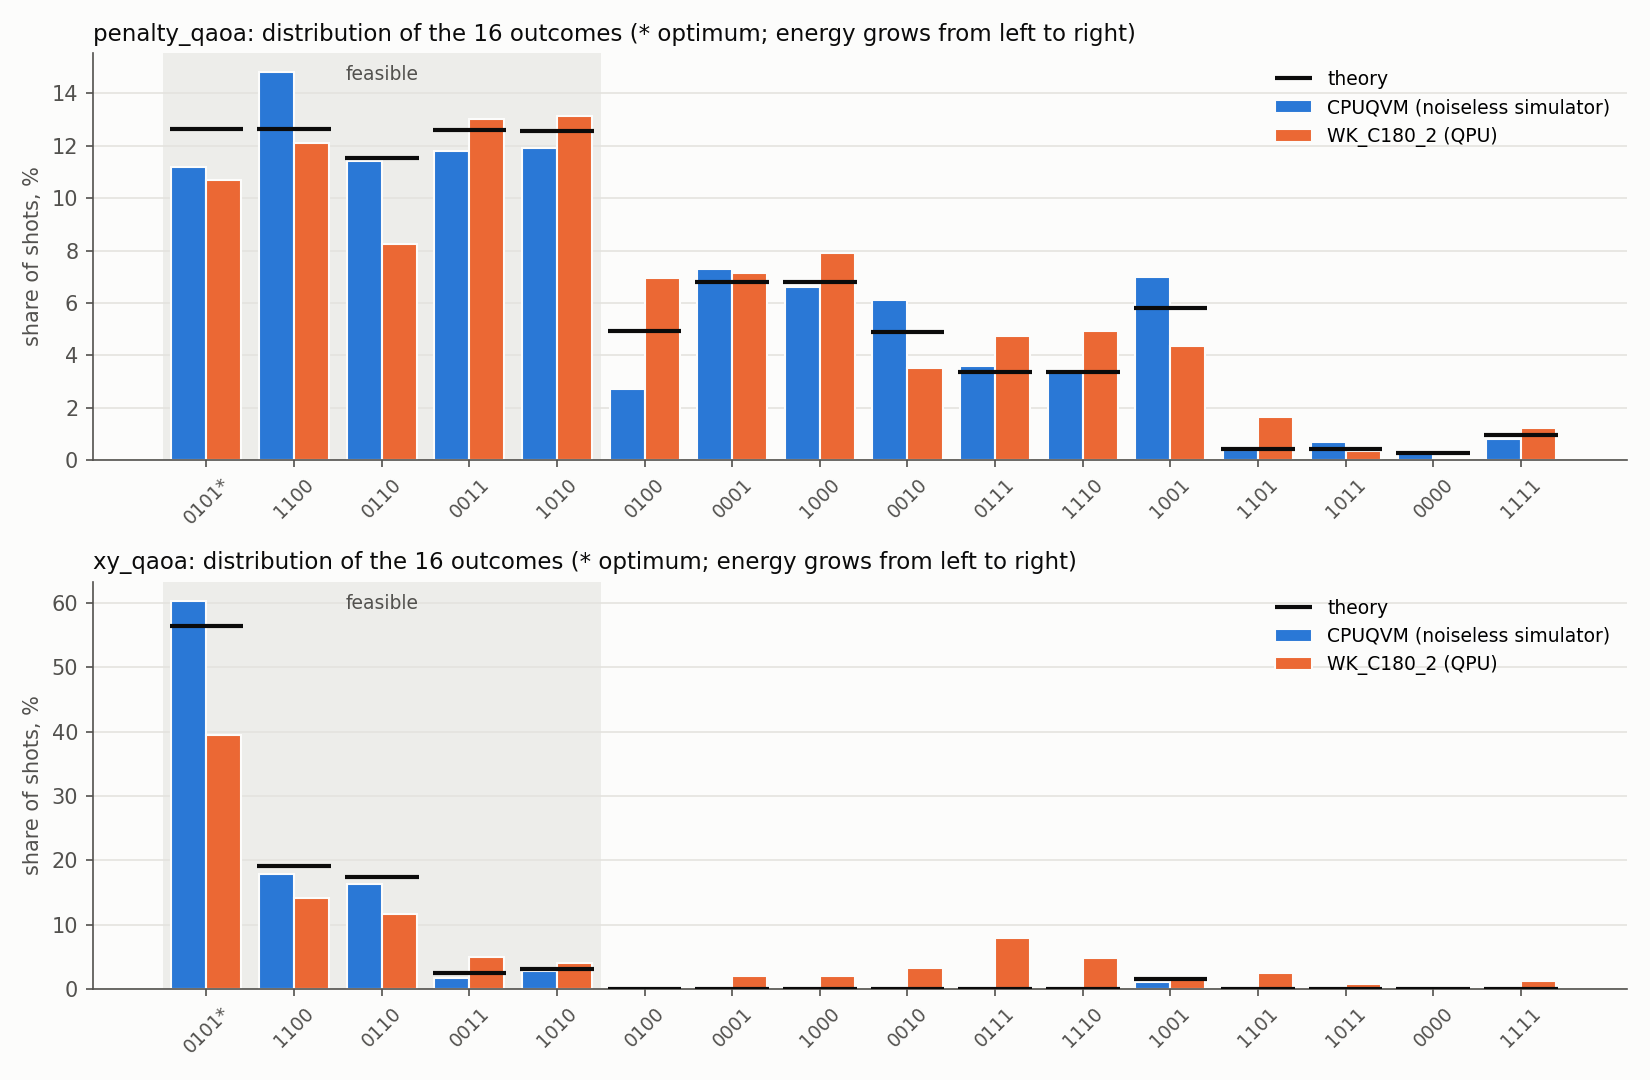

In [9]:
# ===== src/step5_analysis.py (project file, 1:1) =====
# -*- coding: utf-8 -*-
"""
Step 5. Results analysis: theory vs simulators vs quantum computer.

What it does: collects everything that is available - theory (step 2), CPUQVM (step 3), cloud simulator and QPU
(step 4), converts the backends' answers into one bit order, computes the metrics and prints conclusions.
Steps 3 and 4 are optional: the analysis uses whichever sources are ready.

Metrics (for every circuit and every source):
  P(opt)       - share of shots with the optimal answer 0101;
  P(feas)      - share of feasible answers (exactly 2 lines and no short circuit);
  P(opt|feas)  - share of the optimum among feasible answers: can the circuit pick the best feasible state
                 (a random choice among the 5 feasible states gives 20%);
  <H>          - mean energy of the answer (lower is better);
  rank         - place of the optimum among feasible states by frequency (1 = most frequent);
  TVD          - distance to theory: 0 - identical, 1 - nothing in common.

Input:  results/step1..step4 (whatever exists)
Output: results/step5_report.md, results/step5_plot.png
Run:    python src/step5_analysis.py      (in Jupyter: %run src/step5_analysis.py)
"""
import importlib
import os
import sys
import time
from datetime import datetime

import numpy as np

# Shared functions: if the code of common.py was pasted into a notebook cell above, take them from there,
# otherwise import the file src/common.py (run via python or %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Shared functions are missing: run the cell with the code of src/common.py first "
                         "(or put the file src/common.py next to this one).")
    C = importlib.reload(C)   # Jupyter caches modules: reload in case common.py was updated

MAIN = ["penalty_qaoa", "xy_qaoa", "legacy_qaoa"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]          # validated palette: blue, orange, teal
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"


def collect_sources(P, exact):
    """[(label, analysis)] for every finished source with measurements."""
    out = []
    if os.path.exists(C.STEP3_PATH):
        s3 = C.load_json(C.STEP3_PATH, "step 3")
        out.append(("CPUQVM (noiseless simulator)", C.analyse_raw(P, exact, s3["raw"])))
    if os.path.exists(C.STEP4_PATH):
        s4 = C.load_json(C.STEP4_PATH, "step 4")
        for t in s4["tiers"]:
            if t["status"] == "done":
                label = f"{t['backend']} ({'QPU' if t.get('type') == 'qpu' else 'cloud simulator'})"
                out.append((label, C.analyse_raw(P, exact, t["raw"])))
            else:
                print(f"   {t['backend']}: {'still running' if t['status'] == 'pending' else 'error'} - "
                      f"not included in the analysis")
    return out


def rows_for(P, exact, sources, name):
    uni = np.full(2 ** P.n, 1 / 2 ** P.n)
    rows = [("random guess", C.metrics(P, uni, exact[name])),
            ("theory (noiseless)", C.metrics(P, exact[name], exact[name]))]
    rows += [(label, a["metrics"][name]) for label, a in sources if name in a["metrics"]]
    return rows


def fmt_row(label, m):
    pof = m["p_opt_given_feasible"]
    return (f"| {label} | {m['p_opt']:.1%} | {m['p_feasible']:.1%} | "
            f"{(f'{pof:.1%}' if pof is not None else '-')} | {m['exp_H']:.2f} | {m['mode']} | "
            f"{m['opt_rank_among_feasible']} | {m['tvd']:.3f} |")


def conclusions(P, exact, sources):
    opt = P.opt_strings()[0]
    k_opt = int(opt, 2)
    n_states = 2 ** P.n
    rnd_f = 1.0 / int(P.feasible.sum())          # random choice among the feasible states
    lines = []
    for label, a in sources:                      # headline for every quantum computer
        if "(QPU)" not in label or not a["metrics"]:
            continue
        best = max(a["metrics"], key=lambda c: a["metrics"][c]["p_opt"])
        m = a["metrics"][best]
        place = ("the most frequent outcome" if m["mode"] == opt
                 else f"rank {m['opt_rank_among_feasible']} among feasible states")
        lines.append(f"- **Summary, {label}:** the best circuit is {best}. The optimum {opt} is {place}: "
                     f"P(opt) = {m['p_opt']:.1%} ({m['p_opt'] * n_states:.1f}x a random guess), "
                     f"P(opt|feas) = {m['p_opt_given_feasible']:.0%} (random choice {rnd_f:.0%}).")
    for name in [c for c in MAIN if c in exact]:
        th_popt = float(exact[name][k_opt])
        series = [("theory", exact[name], False)] + [(lbl, a["probs"][name], "(QPU)" in lbl)
                                                      for lbl, a in sources if name in a["probs"]]
        for label, p, is_qpu in series:
            m = C.metrics(P, p)
            margin = m["p_opt"] - max(p[k] for k in range(n_states) if k != k_opt)
            if m["mode"] == opt:
                where = (f"the most frequent outcome, but only {100 * margin:.1f} pp ahead of the next one "
                         f"(effectively a tie)" if margin < 0.01
                         else f"the most frequent outcome ({100 * margin:.1f} pp ahead of the next one)")
            else:
                where = (f"not the most frequent outcome (most frequent: {m['mode']}; the optimum is "
                         f"rank {m['opt_rank_among_feasible']} among feasible states)")
            pof = m["p_opt_given_feasible"]
            if pof >= 1.5 * rnd_f:
                select = f"it is selected among feasible states: {pof:.0%} vs {rnd_f:.0%} for a random choice"
            elif pof >= 0.8 * rnd_f:
                select = f"it is not selected among feasible states: {pof:.0%}, close to a random choice ({rnd_f:.0%})"
            else:
                select = f"among feasible states it is below a random choice: {pof:.0%} vs {rnd_f:.0%}"
            keep = (f"; the chip keeps {m['p_opt'] / th_popt:.0%} of the noiseless P(opt)"
                    if is_qpu and th_popt > 0 else "")
            lines.append(f"- **{name}, {label}:** the optimum {opt} is {where}; P(opt) = {m['p_opt']:.1%} "
                         f"({m['p_opt'] * n_states:.1f}x a random guess){keep}; {select}.")
    for label, a in sources:
        side = "rightmost" if a["order"] == "q0_right" else "leftmost"
        lines.append(f"- Bit order, {label}: qubit 0 is the {side} character of the key "
                     f"(calibration {a['calib_top']!r}, {a['calib_share']:.0%}).")
    return lines


def plot(P, exact, sources, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    names = [c for c in ("penalty_qaoa", "xy_qaoa") if c in exact]
    order = sorted(range(2 ** P.n), key=lambda k: P.E[k])
    labels = [C.xstr(k, P.n) + ("*" if P.optimal[k] else "") for k in order]
    nfeas = int(P.feasible.sum())
    fig, axes = plt.subplots(len(names), 1, figsize=(11, 3.6 * len(names)), facecolor=SURFACE, squeeze=False)
    for ax, name in zip(axes[:, 0], names):
        ax.set_facecolor(SURFACE)
        ax.axvspan(-0.5, nfeas - 0.5, color=GRID, alpha=0.6, lw=0, zorder=0)
        ax.text(nfeas / 2 - 0.5, 0.97, "feasible", transform=ax.get_xaxis_transform(), ha="center",
                va="top", color=INK2, fontsize=9)
        m = len(sources)
        width = 0.8 / max(m, 1)
        xs = np.arange(len(order))
        for i, (label, a) in enumerate(sources[:3]):
            if name not in a["probs"]:
                continue
            ys = [100 * a["probs"][name][k] for k in order]
            ax.bar(xs - 0.4 + width * (i + 0.5), ys, width, color=COLORS[i], label=label,
                   edgecolor=SURFACE, linewidth=1.0, zorder=2)
        th = [100 * exact[name][k] for k in order]
        ax.hlines(th, xs - 0.42, xs + 0.42, colors=INK, linewidth=2, label="theory", zorder=3)
        ax.set_xticks(xs)
        ax.set_xticklabels(labels, rotation=45, fontsize=9, color=INK2)
        ax.set_ylabel("share of shots, %", color=INK2)
        ax.set_title(f"{name}: distribution of the 16 outcomes (* optimum; energy grows from left to right)",
                     loc="left", fontsize=11, color=INK)
        ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=1)
        ax.tick_params(colors=INK2)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        for s in ("left", "bottom"):
            ax.spines[s].set_color(INK2)
        ax.legend(loc="upper right", frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(path, dpi=150, facecolor=SURFACE)
    plt.close(fig)


def main():
    t0 = time.time()
    s2, P, gates, exact = C.load_circuits()
    print("=" * 72)
    print("STEP 5. Analysis: theory, simulators, quantum computer")
    print("=" * 72)
    sources = collect_sources(P, exact)
    if not sources:
        print("   no measurements yet - comparing with theory only (run step 3 and/or step 4)")

    md = [f"# Step 5. Results analysis", "",
          f"Created: {datetime.now().isoformat(timespec='seconds')}. Optimum of the problem: {P.opt_strings()} "
          f"(H = {P.E_opt:.3f}). Sources: theory" + "".join(f", {lbl}" for lbl, _ in sources) + ".", ""]
    header = "| source | P(opt) | P(feas) | P(opt\\|feas) | ⟨H⟩ | most frequent | optimum rank | TVD |"
    for name in [c for c in MAIN if c in exact]:
        md += [f"## {name} - {s2['circuits'][name]['title']}", "", header, "|---|---|---|---|---|---|---|---|"]
        md += [fmt_row(label, m) for label, m in rows_for(P, exact, sources, name)]
        md.append("")
        print(f"\n{name} ({s2['circuits'][name]['title']}):")
        print(f"   {'source':<36}{'P(opt)':>8}{'P(feas)':>9}{'P(opt|f)':>10}{'<H>':>8}  {'mode':<7}{'rank':>5}{'TVD':>7}")
        for label, m in rows_for(P, exact, sources, name):
            pof = m["p_opt_given_feasible"]
            print(f"   {label[:35]:<36}{m['p_opt']:8.1%}{m['p_feasible']:9.1%}"
                  f"{(f'{pof:.1%}' if pof is not None else '-'):>10}{m['exp_H']:8.2f}  {m['mode']:<7}"
                  f"{str(m['opt_rank_among_feasible']):>5}{m['tvd']:7.3f}")

    order = sorted(range(2 ** P.n), key=lambda k: P.E[k])
    for name in [c for c in ("penalty_qaoa", "xy_qaoa") if c in exact]:
        md += [f"### {name}: probabilities of all 16 outcomes, %", "",
               "| x | H | feasible | theory | " + " | ".join(lbl for lbl, _ in sources) + " |",
               "|---|---|---|---|" + "---|" * len(sources)]
        for k in order:
            cells = [f"{100 * a['probs'][name][k]:.1f}" if name in a["probs"] else "-" for _, a in sources]
            md.append(f"| {C.xstr(k, P.n)}{' *' if P.optimal[k] else ''} | {P.E[k]:.1f} | "
                      f"{'yes' if P.feasible[k] else '-'} | {100 * exact[name][k]:.1f} | " + " | ".join(cells) + " |")
        md.append("")

    concl = conclusions(P, exact, sources)
    md += ["## Conclusions", ""] + concl + ["", f"![Plot](step5_plot.png)", ""]
    print("\nConclusions:")
    for line in concl:
        print("   " + line.replace("**", ""))

    plot(P, exact, sources, C.STEP5_PLOT)
    os.makedirs(C.RESULTS_DIR, exist_ok=True)
    with open(C.STEP5_REPORT, "w", encoding="utf-8") as f:
        f.write("\n".join(md))
    print(f"\nSaved: {C.rel(C.STEP5_REPORT)}, {C.rel(C.STEP5_PLOT)}   ({time.time() - t0:.1f} s)")
    try:                                     # in Jupyter show the plot right below the cell
        from IPython import get_ipython
        if get_ipython() is not None:
            from IPython.display import Image, display
            display(Image(filename=C.STEP5_PLOT))
    except Exception:  # noqa: BLE001
        pass


if __name__ == "__main__":
    main()